# 01 - Exploratory analysis and SQL aggregation

**Business question.** Planners at a packaging distributor build weekly replenishment plans from
spreadsheet exports of order lines and inventory. Before improving the forecast, we need to know
what the demand looks like: how strong are seasonality, trend and promotions, and how well does
current inventory line up with demand?

This notebook loads the raw tables into an in-memory SQLite database and answers those questions
with SQL (CTEs, joins and window functions), the same queries that would run against the
warehouse. It ends by writing a clean weekly SKU x location sales table used by the forecasting
notebook.

Data: synthetic, generated by `src/generate_data.py` (see README).

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

## 1. Load raw tables into SQLite

Each CSV becomes a table. Indexes on the join keys keep the aggregation queries fast.

In [2]:
con = sqlite3.connect(":memory:")
tables = ["transactions", "products", "locations", "customers", "promotions",
          "inventory_snapshots", "purchase_orders"]
for t in tables:
    df = pd.read_csv(RAW / f"{t}.csv")
    df.to_sql(t, con, index=False)
    print(f"{t:22s} {len(df):>9,d} rows  {df.shape[1]} cols")

con.executescript('''
CREATE INDEX ix_tx_sku_loc_date ON transactions(sku_id, location_id, order_date);
CREATE INDEX ix_inv ON inventory_snapshots(sku_id, location_id, snapshot_date);
CREATE INDEX ix_promo ON promotions(sku_id, start_date, end_date);
''')

def q(sql: str) -> pd.DataFrame:
    return pd.read_sql_query(sql, con)

transactions             372,082 rows  8 cols
products                      60 rows  7 cols
locations                      4 rows  4 cols
customers                    420 rows  4 cols
promotions                   321 rows  5 cols
inventory_snapshots       37,440 rows  6 cols
purchase_orders            9,764 rows  6 cols


## 2. Data quality checks

Basic checks before aggregating: date coverage, nulls, non-positive quantities, orphan keys.

In [3]:
q('''
SELECT MIN(order_date) AS first_order, MAX(order_date) AS last_order,
       COUNT(DISTINCT order_id) AS orders, COUNT(*) AS order_lines,
       COUNT(DISTINCT sku_id) AS skus, COUNT(DISTINCT location_id) AS locations,
       COUNT(DISTINCT customer_id) AS customers,
       SUM(quantity <= 0) AS non_positive_qty,
       SUM(unit_price IS NULL) AS null_prices
FROM transactions
''').T

,0
first_order,2023-01-02
last_order,2025-12-28
orders,151989
order_lines,372082
skus,60
locations,4
customers,420
non_positive_qty,0
null_prices,0


In [4]:
q('''
SELECT 'sku not in products' AS check_name, COUNT(*) AS n
FROM transactions t LEFT JOIN products p USING (sku_id) WHERE p.sku_id IS NULL
UNION ALL
SELECT 'customer not in customers', COUNT(*)
FROM transactions t LEFT JOIN customers c USING (customer_id) WHERE c.customer_id IS NULL
UNION ALL
SELECT 'snapshot sku-location without sales', COUNT(*)
FROM (SELECT DISTINCT sku_id, location_id FROM inventory_snapshots) s
LEFT JOIN (SELECT DISTINCT sku_id, location_id FROM transactions) t USING (sku_id, location_id)
WHERE t.sku_id IS NULL
''')

,check_name,n
0,sku not in products,0
1,customer not in customers,0
2,snapshot sku-location without sales,0


## 3. Weekly SKU x location sales (the forecasting grain)

Order lines are rolled up to ISO weeks (Monday start). A calendar CTE cross-joined with every
SKU-location makes sure weeks with zero sales appear as zeros instead of missing rows, and a join
to the promotions calendar flags promoted weeks.

In [5]:
weekly_sql = '''
WITH RECURSIVE calendar(week_start) AS (
    SELECT DATE('2023-01-02')
    UNION ALL
    SELECT DATE(week_start, '+7 days') FROM calendar WHERE week_start < DATE('2025-12-22')
),
grid AS (
    SELECT p.sku_id, l.location_id, c.week_start
    FROM products p CROSS JOIN locations l CROSS JOIN calendar c
),
tx_week AS (
    SELECT sku_id, location_id,
           DATE(order_date, 'weekday 0', '-6 days') AS week_start,
           SUM(quantity)                 AS units,
           SUM(quantity * unit_price)    AS revenue,
           COUNT(DISTINCT order_id)      AS orders
    FROM transactions
    GROUP BY 1, 2, 3
),
promo_week AS (
    SELECT g.sku_id, g.week_start, MAX(pr.discount_pct) AS promo_discount
    FROM (SELECT DISTINCT sku_id, week_start FROM grid) g
    JOIN promotions pr
      ON pr.sku_id = g.sku_id
     AND pr.start_date <= DATE(g.week_start, '+6 days')
     AND pr.end_date   >= g.week_start
    GROUP BY 1, 2
)
SELECT g.sku_id, g.location_id, g.week_start,
       CAST((JULIANDAY(g.week_start) - JULIANDAY('2023-01-02')) / 7 AS INTEGER) AS week,
       COALESCE(t.units, 0)          AS units,
       ROUND(COALESCE(t.revenue, 0), 2) AS revenue,
       COALESCE(t.orders, 0)         AS orders,
       COALESCE(pw.promo_discount, 0) AS promo_discount
FROM grid g
LEFT JOIN tx_week t    ON t.sku_id = g.sku_id AND t.location_id = g.location_id AND t.week_start = g.week_start
LEFT JOIN promo_week pw ON pw.sku_id = g.sku_id AND pw.week_start = g.week_start
ORDER BY 1, 2, 3
'''
weekly = q(weekly_sql)
weekly.to_sql("weekly_sales", con, index=False)
print(weekly.shape, "| series:", weekly.groupby(["sku_id", "location_id"]).ngroups,
      "| weeks:", weekly.week.nunique())
print("zero-sales share of series-weeks:", round((weekly.units == 0).mean(), 4))
weekly.head()

(37440, 8) | series: 240 | weeks: 156
zero-sales share of series-weeks: 0.009


,sku_id,location_id,week_start,week,units,revenue,orders,promo_discount
0,SKU0001,DC01,2023-01-02,0,1000,2315.0,7,0.0
1,SKU0001,DC01,2023-01-09,1,1600,3745.9,9,0.0
2,SKU0001,DC01,2023-01-16,2,1800,4173.7,9,0.0
3,SKU0001,DC01,2023-01-23,3,1800,4173.8,11,0.0
4,SKU0001,DC01,2023-01-30,4,1100,2571.0,7,0.0


## 4. Demand trend and seasonality by category

Category revenue per month shows the shape of demand. Seasonality is quantified as a monthly index
(month average / annual average) per category.

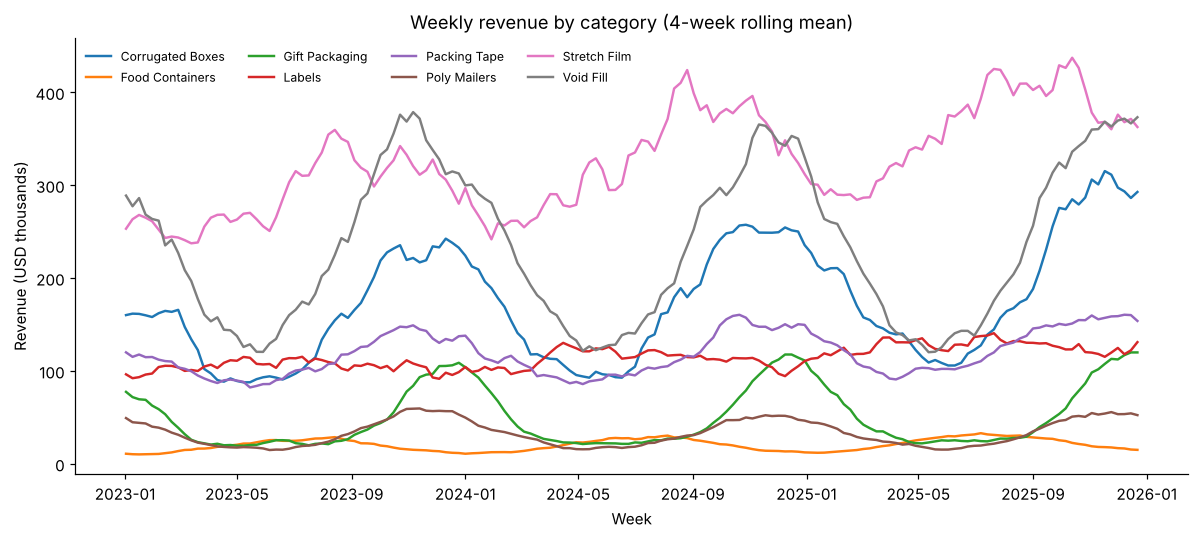

In [6]:
cat_week = q('''
SELECT p.category, w.week_start, SUM(w.units) AS units, SUM(w.revenue) AS revenue
FROM weekly_sales w JOIN products p USING (sku_id)
GROUP BY 1, 2 ORDER BY 1, 2
''')
cat_week["week_start"] = pd.to_datetime(cat_week.week_start)

fig, ax = plt.subplots(figsize=(11, 5))
for cat, g in cat_week.groupby("category"):
    s = g.set_index("week_start").revenue.rolling(4, min_periods=1).mean() / 1e3
    ax.plot(s.index, s.values, label=cat, lw=1.6)
ax.set_title("Weekly revenue by category (4-week rolling mean)")
ax.set_xlabel("Week"); ax.set_ylabel("Revenue (USD thousands)")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "01_category_revenue_trend.png", bbox_inches="tight")
plt.show()

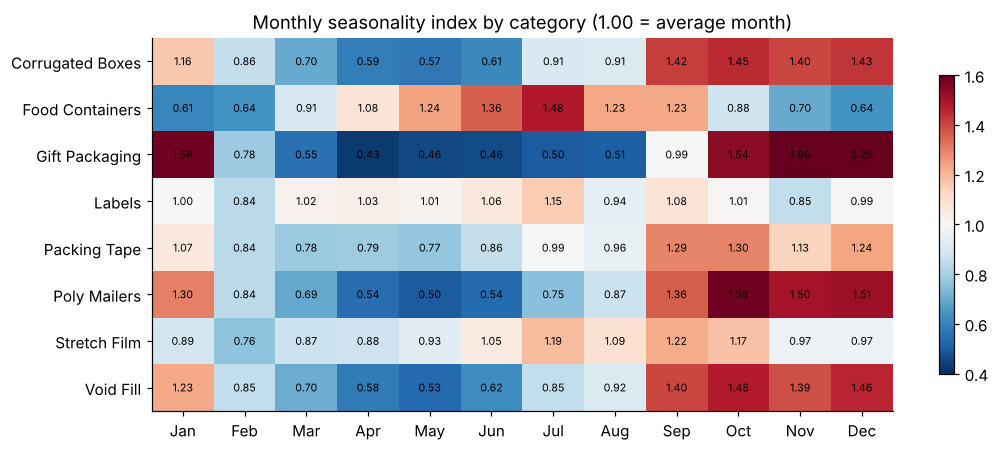

category
Gift Packaging      1.82
Poly Mailers        1.08
Void Fill           0.94
Corrugated Boxes    0.88
Food Containers     0.88
Packing Tape        0.53
Stretch Film        0.46
Labels              0.32
Name: peak_minus_trough, dtype: float64

In [7]:
season = q('''
WITH monthly AS (
    SELECT p.category,
           CAST(STRFTIME('%m', w.week_start) AS INTEGER) AS month,
           STRFTIME('%Y', w.week_start) AS year,
           SUM(w.units) AS units
    FROM weekly_sales w JOIN products p USING (sku_id)
    GROUP BY 1, 2, 3
),
avg_month AS (
    SELECT category, month, AVG(units) AS avg_units FROM monthly GROUP BY 1, 2
)
SELECT category, month,
       avg_units / AVG(avg_units) OVER (PARTITION BY category) AS season_index
FROM avg_month
''')
idx = season.pivot(index="category", columns="month", values="season_index")

fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(idx.values, cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(idx)), idx.index)
for i in range(idx.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{idx.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Monthly seasonality index by category (1.00 = average month)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); fig.savefig(FIG / "01_seasonality_index.png", bbox_inches="tight")
plt.show()
season_range = (idx.max(axis=1) - idx.min(axis=1)).sort_values(ascending=False).round(2)
season_range.rename("peak_minus_trough")

## 5. Year-over-year growth and SKU concentration

YoY growth uses a self-join on year; the Pareto query uses a running-sum window function.

In [8]:
yoy = q('''
WITH yearly AS (
    SELECT p.category, STRFTIME('%Y', w.week_start) AS year, SUM(w.revenue) AS revenue
    FROM weekly_sales w JOIN products p USING (sku_id)
    WHERE w.week_start >= '2023-01-02'
    GROUP BY 1, 2
)
SELECT a.category, ROUND(a.revenue) AS revenue_2025,
       ROUND(100.0 * (b.revenue - c.revenue) / c.revenue, 1) AS yoy_2024_pct,
       ROUND(100.0 * (a.revenue - b.revenue) / b.revenue, 1) AS yoy_2025_pct
FROM yearly a
JOIN yearly b ON b.category = a.category AND b.year = '2024'
JOIN yearly c ON c.category = a.category AND c.year = '2023'
WHERE a.year = '2025'
ORDER BY revenue_2025 DESC
''')
yoy

,category,revenue_2025,yoy_2024_pct,yoy_2025_pct
0,Stretch Film,18503880.0,13.9,7.1
1,Void Fill,12087836.0,0.0,-2.3
2,Corrugated Boxes,9982742.0,12.3,9.3
3,Labels,6473196.0,9.4,8.3
4,Packing Tape,6463237.0,5.8,3.9
5,Gift Packaging,2745760.0,13.9,-0.3
6,Poly Mailers,1706698.0,-3.2,-0.6
7,Food Containers,1162186.0,8.1,10.1


In [9]:
pareto = q('''
WITH sku_rev AS (
    SELECT sku_id, SUM(revenue) AS revenue FROM weekly_sales
    WHERE week_start >= '2025-01-01' GROUP BY 1
)
SELECT sku_id, revenue,
       SUM(revenue) OVER (ORDER BY revenue DESC ROWS UNBOUNDED PRECEDING) * 1.0
         / SUM(revenue) OVER () AS cum_share,
       ROW_NUMBER() OVER (ORDER BY revenue DESC) AS rank
FROM sku_rev
''')
top20 = pareto.loc[pareto["rank"] <= round(0.2 * len(pareto)), "revenue"].sum() / pareto.revenue.sum()
print(f"Top 20% of SKUs = {top20:.1%} of 2025 revenue")

Top 20% of SKUs = 61.3% of 2025 revenue


## 6. Promotion lift

Lift is measured within SKU-location: average weekly units in promoted weeks against the
average of the 8 surrounding non-promoted weeks (a simple pre/post baseline, written with a
window function).

In [10]:
lift = q('''
WITH base AS (
    SELECT sku_id, location_id, week, units, promo_discount,
           AVG(CASE WHEN promo_discount = 0 THEN units END)
             OVER (PARTITION BY sku_id, location_id ORDER BY week
                   ROWS BETWEEN 4 PRECEDING AND 4 FOLLOWING) AS local_baseline
    FROM weekly_sales
)
SELECT promo_discount, COUNT(*) AS promo_weeks,
       ROUND(SUM(units) * 1.0 / SUM(local_baseline), 3) AS lift
FROM base
WHERE promo_discount > 0 AND local_baseline > 0
GROUP BY 1 ORDER BY 1
''')
lift

,promo_discount,promo_weeks,lift
0,0.08,528,1.132
1,0.10,416,1.179
2,0.12,480,1.276
3,0.15,468,1.286
4,0.20,596,1.331


## 7. Inventory position versus demand (current planning rule)

Weekly snapshots are joined to the same week's sales. Weeks of cover is on-hand divided by the
trailing 8-week average demand. We also look forward: stock that will not be needed within the
next 8 weeks of actual demand is counted as **excess**.

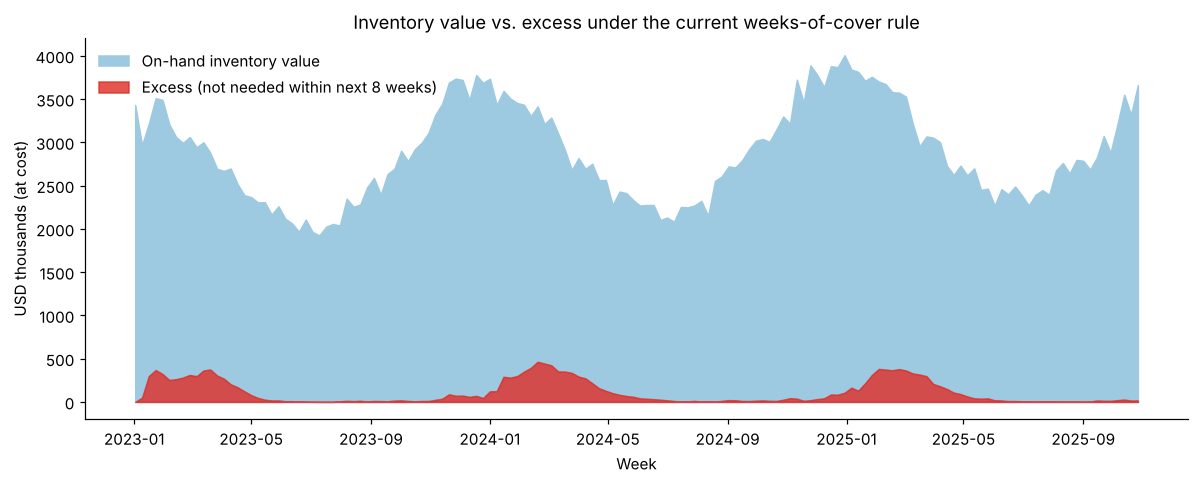

avg weekly inventory value (USD)               2879922.400
avg weekly excess value (USD)                   109466.229
excess share of inventory value                      0.038
median weeks of cover                                3.980
share of SKU-location-weeks with backorders          0.009
dtype: float64

In [11]:
inv = q('''
WITH s AS (
    SELECT i.sku_id, i.location_id, DATE(i.snapshot_date, '-6 days') AS week_start,
           i.on_hand_units, i.backorder_units, p.unit_cost, p.category
    FROM inventory_snapshots i JOIN products p USING (sku_id)
),
d AS (
    SELECT sku_id, location_id, week_start, week, units,
           AVG(units) OVER w_back AS avg8_back,
           SUM(units) OVER w_fwd  AS next8_units,
           COUNT(*)   OVER w_fwd  AS fwd_weeks
    FROM weekly_sales
    WINDOW w_back AS (PARTITION BY sku_id, location_id ORDER BY week ROWS BETWEEN 7 PRECEDING AND CURRENT ROW),
           w_fwd  AS (PARTITION BY sku_id, location_id ORDER BY week ROWS BETWEEN 1 FOLLOWING AND 8 FOLLOWING)
)
SELECT s.*, d.week, d.units, d.avg8_back, d.next8_units, d.fwd_weeks,
       s.on_hand_units / NULLIF(d.avg8_back, 0) AS weeks_of_cover,
       MAX(s.on_hand_units - d.next8_units, 0) AS excess_units
FROM s JOIN d USING (sku_id, location_id, week_start)
''')
inv["week_start"] = pd.to_datetime(inv.week_start)
inv["inventory_value"] = inv.on_hand_units * inv.unit_cost
inv["excess_value"] = inv.excess_units * inv.unit_cost
full = inv[inv.fwd_weeks == 8]

by_week = full.groupby("week_start")[["inventory_value", "excess_value"]].sum() / 1e3
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(by_week.index, by_week.inventory_value, color="#9ecae1", label="On-hand inventory value")
ax.fill_between(by_week.index, by_week.excess_value, color="#de2d26", alpha=0.8,
                label="Excess (not needed within next 8 weeks)")
ax.set_title("Inventory value vs. excess under the current weeks-of-cover rule")
ax.set_xlabel("Week"); ax.set_ylabel("USD thousands (at cost)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "01_inventory_excess_current.png", bbox_inches="tight")
plt.show()

summary = pd.Series({
    "avg weekly inventory value (USD)": full.groupby("week_start").inventory_value.sum().mean(),
    "avg weekly excess value (USD)": full.groupby("week_start").excess_value.sum().mean(),
    "excess share of inventory value": full.excess_value.sum() / full.inventory_value.sum(),
    "median weeks of cover": full.weeks_of_cover.median(),
    "share of SKU-location-weeks with backorders": (full.backorder_units > 0).mean(),
})
summary.round(3)

In [12]:
by_month = (full.assign(month=full.week_start.dt.month)
            .groupby("month")[["excess_value", "inventory_value"]].sum())
(by_month.excess_value / by_month.inventory_value).round(3).rename("excess_share_by_month")

month
1     0.060
2     0.106
3     0.110
4     0.068
5     0.022
6     0.007
7     0.002
8     0.002
9     0.004
10    0.005
11    0.012
12    0.017
Name: excess_share_by_month, dtype: float64

## 8. Write processed outputs

In [13]:
weekly.to_csv(PROC / "weekly_sales.csv", index=False)
print("weekly_sales.csv:", weekly.shape)

weekly_sales.csv: (37440, 8)


## Findings

* Data quality is clean enough to aggregate directly: 372,082 order lines (151,989 orders) for
  60 SKUs x 4 DCs from 2023-01-02 to 2025-12-28, with no orphan keys, no non-positive quantities
  and no missing prices. Only 0.9% of SKU-DC-weeks have zero sales.
* Seasonality differs sharply by category. The peak-to-trough range of the monthly index is 1.82
  for Gift Packaging (December spike) and about 0.9-1.1 for Poly Mailers, Void Fill, Corrugated
  Boxes and Food Containers (summer peak for food containers, Q4 for the rest). Labels (0.32) and
  Stretch Film (0.46) are nearly flat. A single moving average cannot fit all of these shapes.
* Trends also differ: in 2025 Corrugated Boxes grew 9.3% YoY, Food Containers 10.1% and Labels
  8.3%, while Void Fill (-2.3%) and Poly Mailers (-0.6%) declined.
* Promotions lift volume: 1.13x at 8% off, rising to 1.33x at 20% off, measured against nearby
  non-promoted weeks. The promotion calendar is a useful forecast input.
* Revenue is concentrated: the top 20% of SKUs bring in 61.3% of 2025 revenue.
* The weeks-of-cover rule holds a median of 3.98 weeks of cover. Its excess stock (inventory not
  needed within the next 8 weeks) is seasonal. It peaks after the Q4 peak, at 10.6% of inventory
  value in February and 11.0% in March, and falls below 1% from June to October. This pattern
  comes from planning on a trailing average.